# Baselines, boosting e corretores opcionais

Antes de combinar modelos, é preciso ter **controles fortes**: uma estrutura composta só vale a pena se superar baselines simples nas mesmas origens. Este notebook mostra os modelos acrescentados na F1 do plano de ensembles:

| Grupo | Modelos | Instalação |
|---|---|---|
| Baselines | `historic_average`, `window_average`, `seasonal_window_average`, `random_walk_drift` | núcleo |
| Boosting sobre lags | `hist_gradient_boosting` (gradient boosting), `adaboost_r2` (AdaBoost.R2), `lightgbm_regressor`, `xgboost_regressor`, `catboost_regressor` | núcleo; LightGBM, XGBoost e CatBoost no extra `boosting` |
| Corretores opcionais | `svm`, `tree`, `random_forest` e os mesmos cinco de boosting | idem |

Todos estão registrados, mas **fora da busca padrão**: entram quando pedidos. Também aparece a métrica RMAE (`MAE / média do observado`, como no protocolo de replicação) e a contagem de ajustes de cada candidata.

In [1]:
import time
import warnings

import matplotlib.pyplot as plt
import pandas as pd

import autohybts
from autohybts import AutoHybridExperiment
from autohybts.datasets import get_data

warnings.filterwarnings("ignore")
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 20)


def clean(ax, grid_axis="both"):
    """Recessive grid and axes; text in neutral ink."""
    ax.grid(axis=grid_axis, color="#e4e3df", linewidth=0.8)
    ax.set_axisbelow(True)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    ax.tick_params(colors="#52514e")


print("AutoHybTS", autohybts.__version__)

AutoHybTS 0.0.1


## 1. Dados e experimento

Série sintética diária (tendência, sazonalidade semanal e ruído AR(0,7)); horizonte de 14 dias, 3 origens em cada camada de validação.

In [2]:
y = get_data("synthetic_daily", n=500)
exp = AutoHybridExperiment(
    fh=14,
    fold=3,
    session_id=42,
    metrics=["MASE", "RMAE", "RRMSE", "sMAPE"],
).fit(y)
exp.models().loc["base"][
    ["family", "multi_step", "online_state_update", "training_scope", "requires_extra"]
]

,family,multi_step,online_state_update,training_scope,requires_extra
name,,,,,
adaboost_r2,tree,True,True,local,NaN
adida,intermittent,True,True,local,NaN
arima,statistical,True,True,local,stats
catboost_regressor,tree,True,True,local,boosting
croston_sba,intermittent,True,True,local,NaN
elastic_net_regression,linear,True,True,local,NaN
exponential_smoothing,statistical,True,True,local,stats
extra_trees_regressor,tree,True,True,local,NaN
harmonic_regression,statistical,True,True,local,NaN


## 2. Cada modelo nas mesmas origens

MASE e RMAE médias em `V_search` e `V_select`, ajustes por origem e segundos. Nenhum desses números toca o teste selado.

In [3]:
names = [
    "naive",
    "seasonal_naive",
    "historic_average",
    "window_average",
    "seasonal_window_average",
    "random_walk_drift",
    "linear",
    "random_forest",
    "hist_gradient_boosting",
    "adaboost_r2",
    "lightgbm_regressor",
    "xgboost_regressor",
    "catboost_regressor",
]
rows = []
for name in names:
    started = time.perf_counter()
    result = exp.create_model(name)
    frame = result.evaluation.to_frame()
    rows.append(
        {
            "modelo": name,
            "MASE V_search": frame.loc[frame["layer"] == "search", "MASE"].mean(),
            "MASE V_select": frame.loc[frame["layer"] == "select", "MASE"].mean(),
            "RMAE V_select": frame.loc[frame["layer"] == "select", "RMAE"].mean(),
            "ajustes/origem": result.evaluation.trials[0].n_fits,
            "status": result.evaluation.trials[0].status,
            "segundos": time.perf_counter() - started,
        }
    )
models = pd.DataFrame(rows).set_index("modelo")
models.round(3).sort_values("MASE V_select")

,MASE V_search,MASE V_select,RMAE V_select,ajustes/origem,status,segundos
modelo,,,,,,
linear,1.222,1.277,0.030,1,SUCCEEDED,2.779
seasonal_window_average,0.948,1.384,0.033,1,SUCCEEDED,0.012
seasonal_naive,1.288,1.522,0.036,1,SUCCEEDED,0.005
adaboost_r2,1.387,1.694,0.040,1,SUCCEEDED,2.712
window_average,1.819,1.787,0.043,1,SUCCEEDED,0.005
xgboost_regressor,1.230,1.795,0.043,1,SUCCEEDED,2.494
lightgbm_regressor,1.340,1.915,0.046,1,SUCCEEDED,0.842
hist_gradient_boosting,1.063,1.976,0.047,1,SUCCEEDED,2.210
random_forest,1.097,2.033,0.048,1,SUCCEEDED,4.926


Cada modelo como um ponto: erro em `V_search` (onde a busca escolhe) contra erro em `V_select` (onde a seleção decide). Acima da diagonal, o modelo piorou da primeira camada para a segunda; longe dela, a primeira camada enganou. Escala logarítmica, porque `historic_average` fica muito acima dos demais.

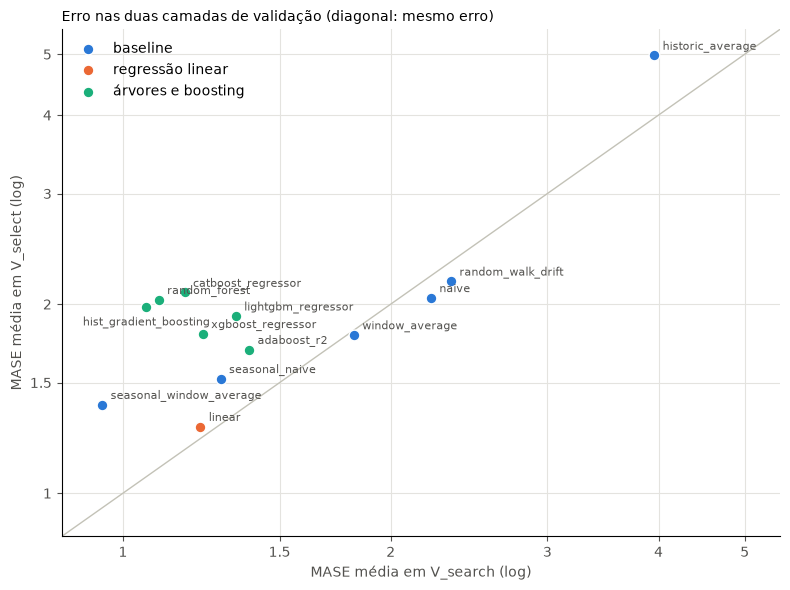

In [4]:
groups = {
    "baseline": [
        "naive",
        "seasonal_naive",
        "historic_average",
        "window_average",
        "seasonal_window_average",
        "random_walk_drift",
    ],
    "regressão linear": ["linear"],
    "árvores e boosting": [
        "random_forest",
        "hist_gradient_boosting",
        "adaboost_r2",
        "lightgbm_regressor",
        "xgboost_regressor",
        "catboost_regressor",
    ],
}
colors = ["#2a78d6", "#eb6834", "#1baf7a"]  # fixed order, one per group
fig, ax = plt.subplots(figsize=(8, 6))
low = models[["MASE V_search", "MASE V_select"]].min().min() * 0.9
high = models[["MASE V_search", "MASE V_select"]].max().max() * 1.1
ax.plot([low, high], [low, high], color="#c3c2b7", linewidth=1, zorder=1)
for (group, names_in_group), color in zip(groups.items(), colors, strict=True):
    part = models.loc[names_in_group]
    ax.scatter(
        part["MASE V_search"],
        part["MASE V_select"],
        s=60,
        color=color,
        edgecolors="white",
        linewidths=1,
        label=group,
        zorder=3,
    )
    for name, row in part.iterrows():
        ax.annotate(
            name,
            (row["MASE V_search"], row["MASE V_select"]),
            xytext=(0, -13) if name == "hist_gradient_boosting" else (6, 4),
            ha="center" if name == "hist_gradient_boosting" else "left",
            textcoords="offset points",
            fontsize=8,
            color="#52514e",
        )
ticks = [1, 1.5, 2, 3, 4, 5]
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlim(low, high)
ax.set_ylim(low, high)
ax.set_xticks(ticks, [f"{t:g}" for t in ticks])
ax.set_yticks(ticks, [f"{t:g}" for t in ticks])
ax.minorticks_off()
ax.set_xlabel("MASE média em V_search (log)", color="#52514e")
ax.set_ylabel("MASE média em V_select (log)", color="#52514e")
ax.set_title("Erro nas duas camadas de validação (diagonal: mesmo erro)", loc="left", fontsize=10)
ax.legend(frameon=False, loc="upper left")
clean(ax)
fig.tight_layout()

## 3. Boosting como corretor de resíduos

O mesmo estimador pode prever o nível (base) ou o erro (corretor). Aqui a base é o `seasonal_naive` e o corretor varia; um híbrido ajusta 3 modelos por origem: a base, a base no prefixo (para os resíduos fora da amostra) e o corretor.

In [5]:
rows = []
for corrector in ["linear", "knn", "random_forest", "hist_gradient_boosting", "lightgbm_regressor"]:
    hybrid = exp.create_hybrid("seasonal_naive", corrector, window=14)
    frame = hybrid.evaluation.to_frame()
    rows.append(
        {
            "corretor": corrector,
            "MASE V_select": frame.loc[frame["layer"] == "select", "MASE"].mean(),
            "ajustes/origem": hybrid.evaluation.trials[0].n_fits,
            "variabilidade": hybrid.evaluation.trials[0].diagnostics.get("correction_std_ratio"),
        }
    )
pd.DataFrame(rows).set_index("corretor").round(3)

,MASE V_select,ajustes/origem,variabilidade
corretor,,,
linear,1.409,3,0.797
knn,1.450,3,0.635
random_forest,1.478,3,0.834
hist_gradient_boosting,1.664,3,0.892
lightgbm_regressor,1.715,3,0.995


## 4. Busca com os modelos opcionais

Passados em `base_models` e `correctors`, entram na busca como os demais. O custo aparece em candidatas, unidades (origem × série) e ajustes.

In [6]:
search = AutoHybridExperiment(
    fh=14,
    fold=3,
    session_id=42,
    budget="small",
    base_models=[
        "naive",
        "seasonal_naive",
        "random_walk_drift",
        "linear",
        "hist_gradient_boosting",
        "lightgbm_regressor",
    ],
    correctors=["linear", "lightgbm_regressor"],
    residual_windows=[14],
    alphas=[1.0],
).fit(y)
result = search.compare_models()
print(
    f"candidatas: {result.search.trial_count}, unidades: {result.search.unit_count}, "
    f"ajustes: {result.search.fit_count}"
)
result.leaderboard[["family", "strategy", "MASE", "coverage"]].head(8).round(3)

candidatas: 18, unidades: 54, ajustes: 132


,family,strategy,MASE,coverage
candidate_id,,,,
54de23ccd986da3e6fa370e64c8384d3f66f1cc1030b087a41ab444726e2d8b5,residual,residual_additive,0.949,1.0
f22b98e4df6b2e091d0ec1c2e886c8b70f21d9716186f857489f3f482d44aea1,tree,standalone,1.063,1.0
5a81a5e3c91d5d3af411b88ccc7daee8ecd51b5782089bf243963fe51a88faf2,residual,residual_additive,1.103,1.0
fe652f4bcb23caf50e5cb9eaf5228d477d9500a9654dec9a1723aaffb17da4ce,residual,residual_additive,1.191,1.0
a2d2e6bef48b83c70955d2cd03f376645564e16a276199e9a7ef14852561b724,residual,residual_additive,1.211,1.0
e9e747a9648ad8d377f20122dce611a43dd3bf85a64c950a8e1ef246ebc032b4,linear,standalone,1.222,1.0
d90528888825a4459816afbcf249ff909747924f0a2bbaa6e09d027e31342238,statistical,standalone,1.288,1.0
d5019a1a6346a1e9fb90408978c64a79b14d03727731053f70fca5a8b33ee79f,tree,standalone,1.340,1.0


In [7]:
result.decisions[
    ["family", "champion_before", "challenger", "accepted", "reason_codes", "median_gain"]
]

,family,champion_before,challenger,accepted,reason_codes,median_gain
0,statistical,hist_gradient_boosting,seasonal_naive,True,"(accepted,)",0.223312
1,linear,seasonal_naive,linear,True,"(accepted,)",0.186763
2,tree,linear,hist_gradient_boosting,False,"(median_gain_below_threshold, win_rate_below_t...",-0.516641
3,residual,linear,seasonal_naive-linear,False,"(median_gain_below_threshold, win_rate_below_t...",-0.076187


Previsões fora da amostra do campeão em cada origem de validação (o teste selado não aparece).

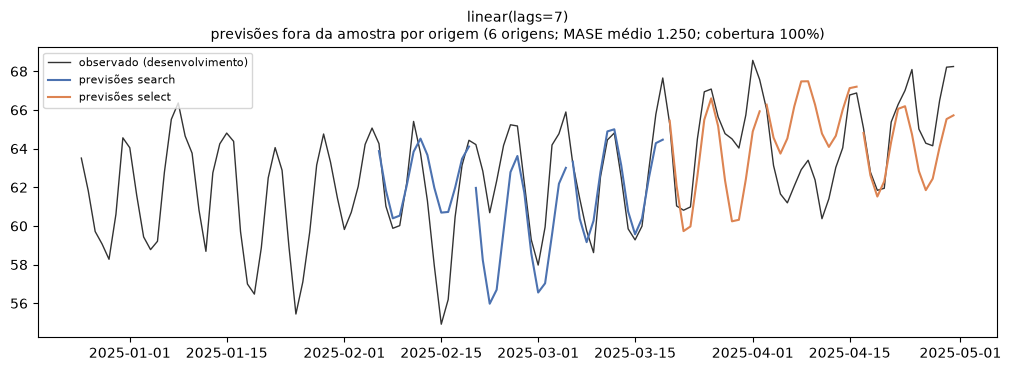

In [8]:
search.plot_model(result.best, "cv_forecasts")

## 5. Leitura

Nesta série (500 pontos, `fh=14`, 3 origens por camada):

* **Baselines importam.** `seasonal_window_average` (MASE 1,38 em `V_select`) ficou à frente do `seasonal_naive` (1,52) e de todos os modelos de boosting; só o `linear` (1,28) foi melhor. `historic_average` (4,98) mostra o custo de ignorar tendência.
* **Boosting não ganhou aqui.** `adaboost_r2` (1,69), `xgboost_regressor` (1,80), `lightgbm_regressor` (1,92), `hist_gradient_boosting` (1,98) e `catboost_regressor` (2,09) ficaram atrás do `linear`. `hist_gradient_boosting`, `catboost_regressor` e a floresta aleatória têm a maior distância entre `V_search` e `V_select` (1,06 → 1,98, 1,17 → 2,09 e 1,10 → 2,03; os pontos mais acima da diagonal na figura): sinal de ajuste à validação, não de capacidade.
* **Como corretores**, os modelos de boosting produziram correções grandes (variabilidade 0,89–1,00) e piores que o corretor linear (1,66–1,72 contra 1,41).
* Na **busca**, o campeão foi o `linear`; o `hist_gradient_boosting` e o melhor híbrido foram recusados com ganho mediano negativo. Custo: 18 candidatas, 54 unidades e 132 ajustes.
* Os tempos da tabela foram medidos com outro processo pesado rodando na mesma máquina; servem para comparar modelos entre si, não como referência absoluta.

Em séries curtas com sazonalidade e tendência suaves, modelos de alta capacidade sobre lags raramente superam baselines bem escolhidos. Eles valem como membros diversos de ensembles (notebook 13), sempre comparados com os mesmos controles.